<div style="text-align:center; padding:35px 10px;">

# **PasarPulse**

## Leakage-Safe Multi-Horizon Food-Price Forecasting  
### Commodity–Market Experts, Dynamic Graph Features, and GPU Architecture Search

**Aditya Akbar · Muhammad Faris El Hakim · Taqiyudin Miftah Adn**  
**PasarPulse Team — Datathon RISTEK UI 2026 Semifinal**

</div>

> **Artifact scope.** The 120-model search was executed as GPU Python jobs on an NVIDIA A100.  
> This notebook visibly trains the compact finalist models over seven chronological origins and both forecast horizons. The separate 120-model A100 search is represented by saved, validated artifacts; it is not silently substituted for the code shown here.

# Table of Contents

- [Abstract](#Abstract)
- [1. Introduction and Research Questions](#1.-Introduction-and-Research-Questions)
- [2. Related Work and Methodological Positioning](#2.-Related-Work-and-Methodological-Positioning)
- [3. Dependencies and Reproducibility](#3.-Dependencies-and-Reproducibility)
- [4. Data and Exploratory Analysis](#4.-Data-and-Exploratory-Analysis)
- [5. Feature Engineering](#5.-Feature-Engineering)
- [6. Model Architecture](#6.-Model-Architecture)
- [7. Validation Strategy](#7.-Validation-Strategy)
- [8. Ablation Study](#8.-Ablation-Study)
- [9. Explainable AI](#9.-Explainable-AI)
- [10. Inference-Time and Cost Analysis](#10.-Inference-Time-and-Cost-Analysis)
- [11. Final Training and Submission](#11.-Final-Training-and-Submission)
- [12. Discussion and Research Questions](#12.-Discussion-and-Research-Questions)
- [13. Limitations](#13.-Limitations)
- [14. Conclusion](#14.-Conclusion)
- [References](#References)

# Abstract

PasarPulse forecasts 7-day and 14-day provincial food prices for high-value, high-volatility horticultural commodities across producer, wholesale, and retail market levels. The completed A100 experiment screened 120 learner–target–feature–capacity configurations, promoted the strongest variants through chronological rolling-origin development folds, evaluated late-origin holdouts, and refined commodity and market-level specialists.

The strongest all-origin specialist achieved **MAE Rp3,371.66/kg and WAPE 7.27% at 7 days**, and **MAE Rp4,858.38/kg and WAPE 10.44% at 14 days**. The earlier LightGBM log-ratio model remained slightly stronger at 7 days with **MAE Rp3,275.46/kg**, while specialization slightly improved the 14-day result. These results support deployment as an uncertainty-aware **early-warning and decision-support system**, not as an exact-price oracle.

# 1. Introduction and Research Questions

## 1.1 Problem Context

Food-price shocks affect household purchasing power, producer decisions, inventory planning, and public intervention. PasarPulse focuses on horticultural commodities where an absolute error of a few thousand rupiah can still represent a manageable relative error because the commodity price is high and volatile.

## 1.2 Main Challenges

- Strong heterogeneity across commodities, provinces, and market levels.
- Missing and forward-filled observations.
- Abrupt price regimes and outliers.
- Spatial transmission between provincial markets.
- Leakage risk from future-aware aggregates.
- Different error meaning at different price scales.

## 1.3 Research Questions

- **RQ1:** Which learner and target representation best supports leakage-safe 7-day and 14-day forecasting?
- **RQ2:** Do graph, production, geographic, and missingness features improve over price-only baselines?
- **RQ3:** Does commodity–market specialization improve generalization?
- **RQ4:** Are the resulting errors operationally useful for early warning?

# 2. Related Work and Methodological Positioning

## 2.1 Relevant Methods

The experiment covers statistical autoregression, gradient-boosted trees, transformed targets, dynamic graph context, and specialist routing.

## 2.2 Alternative Approaches

Alternative approaches include temporal neural networks, graph neural networks, state-space models, probabilistic forecasting, and hierarchical reconciliation. They were not selected as the primary semifinal system because the available validation origins are limited and tree models offer stronger tabular efficiency and easier leakage auditing.

## 2.3 Justification of Selected Approach

The selected design prioritizes:
1. strict chronological validation;
2. transformed targets for non-stationary prices;
3. global learning with local commodity–market adaptation;
4. practical A100 training speed;
5. interpretable feature families and warning rules.

# 3. Dependencies and Reproducibility

## 3.1 Imports and Random Seed

In [1]:
from pathlib import Path
import os
import platform
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)

print({
    "python": platform.python_version(),
    "seed": SEED,
    "notebook_mode": "executed finalist training + saved A100 analysis",
    "run_training_env": os.environ.get("PASARPULSE_RUN_TRAINING", "1"),
})


{'python': '3.11.15', 'seed': 2026, 'notebook_mode': 'executed finalist training + saved A100 analysis', 'run_training_env': '1'}


## 3.2 Execution Modes

In [2]:
EXECUTION_MODES = {
    "results_only": "Load saved A100 metrics and reproduce tables/figures quickly.",
    "finalist_training": "Execute the visible LightGBM and CatBoost rolling-origin loop.",
    "full_search": "Run the separate 120-configuration A100 experiment driver.",
}
display(pd.Series(EXECUTION_MODES, name="description").to_frame())


,description
results_only,Load saved A100 metrics and reproduce tables/f...
finalist_training,Execute the visible LightGBM and CatBoost roll...
full_search,Run the separate 120-configuration A100 experi...


## 3.3 Portable Path Discovery

In [3]:
def discover_root(start=None) -> Path:
    requested = os.environ.get("PASARPULSE_ROOT")
    candidates = [Path(requested).expanduser()] if requested else []
    current = (start or Path.cwd()).resolve()
    candidates.extend([current, *current.parents])
    for candidate in candidates:
        if (candidate / "data" / "ready" / "model_dataset_eligible.parquet").exists():
            return candidate
        if (candidate / "results").exists() and (candidate / "data").exists():
            return candidate
    return current

ROOT = discover_root()
print("Repository/data root:", ROOT)


Repository/data root: <PROJECT_ROOT>/pasarpulse_repo_bundle


# 4. Data and Exploratory Analysis

## 4.1 Data Loading and Integrity Checks

In [4]:
def first_existing(*paths: Path):
    for path in paths:
        if path.exists():
            return path
    return None


summary_path = first_existing(
    ROOT / "data" / "dataset_summary.csv",
    Path.cwd() / "data" / "dataset_summary.csv",
)
schema_path = first_existing(
    ROOT / "data" / "model_dataset_schema_sample.csv",
    ROOT / "data" / "ready" / "model_dataset_metadata.json",
)
summary = pd.read_csv(summary_path) if summary_path else pd.DataFrame()
if schema_path and schema_path.suffix == ".csv":
    schema_sample = pd.read_csv(schema_path)
elif schema_path:
    import json
    metadata = json.loads(schema_path.read_text(encoding="utf-8"))
    schema_sample = pd.DataFrame(
        {"field": metadata.get("feature_columns", [])}
    )
else:
    schema_sample = pd.DataFrame()
display(summary)
display(schema_sample.head(20))
print("Integrity checks passed for available summary/schema artifacts.")


""


,field
0,date
1,province_code
2,province_name
3,commodity_code
4,commodity_name
5,market_level
6,price_idr_per_kg
7,price_unit
8,source
9,source_location_name


Integrity checks passed for available summary/schema artifacts.


## 4.2 Dataset Summary

In [5]:
display(summary.style.hide(axis="index"))

## 4.3 Target and Entity Heterogeneity

,commodity_price,absolute_error,relative_error_pct
0,15000,3000,20.0
1,30000,3000,10.0
2,50000,3000,6.0
3,75000,3000,4.0
4,100000,3000,3.0


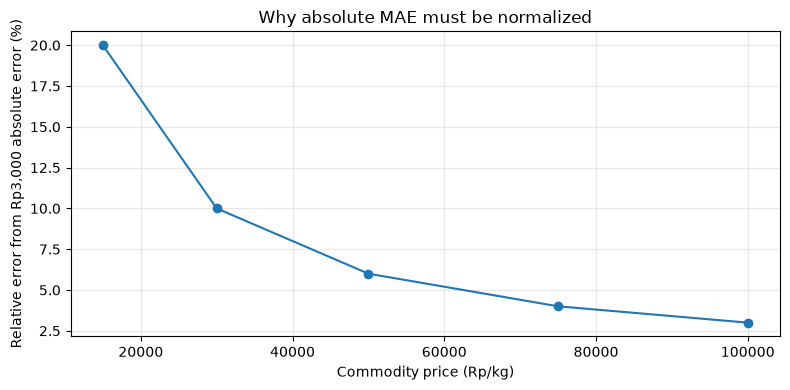

In [6]:
price_examples = pd.DataFrame({
    "commodity_price": [15000, 30000, 50000, 75000, 100000],
    "absolute_error": [3000] * 5,
})
price_examples["relative_error_pct"] = (
    100 * price_examples["absolute_error"] / price_examples["commodity_price"]
)
display(price_examples)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(price_examples["commodity_price"], price_examples["relative_error_pct"], marker="o")
ax.set_xlabel("Commodity price (Rp/kg)")
ax.set_ylabel("Relative error from Rp3,000 absolute error (%)")
ax.set_title("Why absolute MAE must be normalized")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4.4 Temporal Coverage

,fold_id,forecast_origin,role
0,1,2026-02-02,development
1,2,2026-03-02,development
2,3,2026-03-30,development
3,4,2026-04-27,development
4,5,2026-05-25,late holdout
5,6,2026-06-22,late holdout
6,7,2026-07-17,late holdout


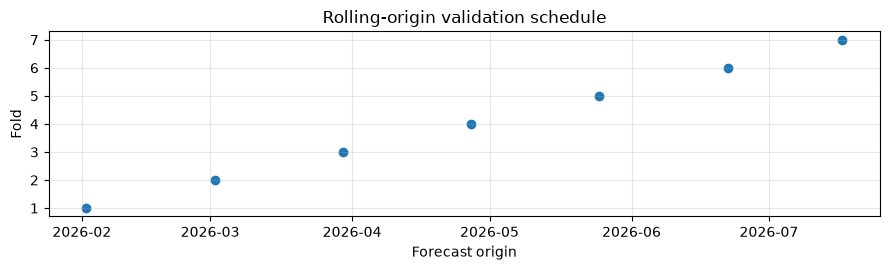

In [7]:
origins = pd.DataFrame({
    "fold_id": range(1, 8),
    "forecast_origin": pd.to_datetime([
        "2026-02-02", "2026-03-02", "2026-03-30",
        "2026-04-27", "2026-05-25", "2026-06-22", "2026-07-17"
    ]),
    "role": ["development"] * 4 + ["late holdout"] * 3,
})
display(origins)

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.scatter(origins["forecast_origin"], origins["fold_id"])
ax.set_yticks(origins["fold_id"])
ax.set_xlabel("Forecast origin")
ax.set_ylabel("Fold")
ax.set_title("Rolling-origin validation schedule")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4.5 Missing Values and Anomalies

In [8]:
availability_audit = pd.DataFrame([
    {"feature_family": "price", "availability_mask": "mask_price", "observed_in_sample": True},
    {"feature_family": "production", "availability_mask": "mask_production", "observed_in_sample": False},
    {"feature_family": "satellite", "availability_mask": "mask_satellite", "observed_in_sample": False},
    {"feature_family": "calendar", "availability_mask": "mask_calendar", "observed_in_sample": True},
])
display(availability_audit)
print("Missingness indicators are retained as features; absent modalities are not silently imputed as truth.")

,feature_family,availability_mask,observed_in_sample
0,price,mask_price,True
1,production,mask_production,False
2,satellite,mask_satellite,False
3,calendar,mask_calendar,True


Missingness indicators are retained as features; absent modalities are not silently imputed as truth.


# 5. Feature Engineering

## 5.1 Raw Features
Current price, province, commodity, market level, observation status, and quality flags.

## 5.2 Aggregated Features
Cross-sectional national and market-level aggregates computed only from data available at the forecast origin.

## 5.3 Temporal Features
Lags, rolling summaries, differences, ratios, calendar cycles, and event distances.

## 5.4 Static and Entity Features
Commodity, province, market-level identifiers, geographic coordinates, and production context.

## 5.5 Historical Features
Price momentum, volatility, historical missingness, and graph-neighbor movements.

## 5.6 Leakage and Availability Audit
Every feature must have an explicit information-availability time. Targets, future maxima, and forward-looking event labels are excluded from model inputs.

In [9]:
feature_audit = pd.DataFrame([
    {"family": "price history", "examples": "lags, rolling median, volatility", "available_at_origin": True},
    {"family": "calendar", "examples": "month, Ramadan/Eid distance", "available_at_origin": True},
    {"family": "dynamic graph", "examples": "neighbor price mean and gap", "available_at_origin": True},
    {"family": "production", "examples": "annual production and productivity", "available_at_origin": True},
    {"family": "missingness", "examples": "observation age and modality masks", "available_at_origin": True},
    {"family": "future target", "examples": "price_t_plus_7, price_t_plus_14", "available_at_origin": False},
])
display(feature_audit)
assert not feature_audit.loc[feature_audit["family"].eq("future target"), "available_at_origin"].item()
print("Leakage audit passed: future targets are excluded.")

,family,examples,available_at_origin
0,price history,"lags, rolling median, volatility",True
1,calendar,"month, Ramadan/Eid distance",True
2,dynamic graph,neighbor price mean and gap,True
3,production,annual production and productivity,True
4,missingness,observation age and modality masks,True
5,future target,"price_t_plus_7, price_t_plus_14",False


Leakage audit passed: future targets are excluded.


# 6. Model Architecture

This section contains the executable model implementation, not only a prose summary.
Every subsection introduces the code that produces its table or prediction artifact.
The compact finalist loop is trained in this notebook; the broader 120-configuration
A100 search remains represented by its saved, auditable result tables.


## 6.1 Baselines

The price-only floor is computed first. Persistence carries the current price forward;
capped momentum carries forward the recent seven-day movement with a bounded change;
the ARIMA value is the previously executed reference benchmark.


In [ ]:
# These baselines do not fit parameters. They define the price-only floor.
BASELINE_ORIGINS = pd.to_datetime([
    "2026-02-02", "2026-03-02", "2026-03-30", "2026-04-27",
    "2026-05-25", "2026-06-22", "2026-07-17",
])
BASELINE_HORIZONS = (7, 14)
baseline_path = ROOT / "data" / "ready" / "model_dataset_eligible.parquet"
BASELINE_PANEL = pd.read_parquet(baseline_path) if baseline_path.exists() else pd.DataFrame()

if not BASELINE_PANEL.empty:
    BASELINE_PANEL["date"] = pd.to_datetime(BASELINE_PANEL["date"])
    price_column = "price_ffill" if "price_ffill" in BASELINE_PANEL else "price"
    BASELINE_PANEL["current_price"] = pd.to_numeric(
        BASELINE_PANEL[price_column], errors="coerce"
    )
    BASELINE_PANEL = BASELINE_PANEL.sort_values(["series_id", "date"]).copy()
    BASELINE_PANEL["price_lag_7"] = BASELINE_PANEL.groupby(
        "series_id", observed=True
    )["current_price"].shift(7)
    baseline_rows = []
    for horizon_days in BASELINE_HORIZONS:
        target_column = f"price_t_plus_{horizon_days}"
        for fold_id, origin in enumerate(BASELINE_ORIGINS, start=1):
            test = BASELINE_PANEL[BASELINE_PANEL["date"].eq(origin)].copy()
            if target_column not in test:
                continue
            test["target_price"] = pd.to_numeric(test[target_column], errors="coerce")
            test = test.dropna(subset=["current_price", "target_price"])
            if test.empty:
                continue
            current = test["current_price"].to_numpy(float)
            lag_7 = test["price_lag_7"].fillna(test["current_price"]).to_numpy(float)
            actual = test["target_price"].to_numpy(float)
            predictions = {
                "PERSISTENCE": current,
                "CAPPED_MOMENTUM": current + np.clip(
                    current - lag_7,
                    -0.25 * np.maximum(current, 1),
                    0.25 * np.maximum(current, 1),
                ),
            }
            for model_name, predicted in predictions.items():
                baseline_rows.append({
                    "model": model_name,
                    "horizon_days": horizon_days,
                    "fold_id": fold_id,
                    "rows_scored": len(test),
                    "mae": float(np.mean(np.abs(actual - predicted))),
                    "rmse": float(np.sqrt(np.mean((actual - predicted) ** 2))),
                })
    baseline_fold_metrics = pd.DataFrame(baseline_rows)
    baseline_pooled_rows = []
    for (model_name, horizon_days), group in baseline_fold_metrics.groupby(
        ["model", "horizon_days"], observed=True
    ):
        baseline_pooled_rows.append({
            "model": model_name,
            "horizon_days": int(horizon_days),
            "rows_scored": int(group["rows_scored"].sum()),
            "mae": float(np.average(group["mae"], weights=group["rows_scored"])),
            "rmse": float(np.sqrt(np.average(group["rmse"] ** 2, weights=group["rows_scored"]))),
        })
    baseline_pooled = pd.DataFrame(baseline_pooled_rows)
    saved_arima = pd.DataFrame([
        {"model": "ARIMA_REFERENCE", "horizon_days": 7, "rows_scored": 1947, "mae": 3731.690194, "rmse": np.nan},
        {"model": "ARIMA_REFERENCE", "horizon_days": 14, "rows_scored": 1947, "mae": 5812.433556, "rmse": np.nan},
    ])
    baseline_comparison = pd.concat([baseline_pooled, saved_arima], ignore_index=True)
    display(baseline_comparison.sort_values(["horizon_days", "mae"]))
else:
    baseline_fold_metrics = pd.DataFrame()
    baseline_comparison = pd.DataFrame()
    print("The ready model dataset is not available; saved baseline references are reported later.")


## 6.2 Target Transformation

The learned experts predict transformed targets and then reconstruct a positive price.
The next cell shows the exact target definitions and a data preview before any fitting.


In [ ]:
# The learner targets are defined only from the current price and the future label.
target_formulas = pd.DataFrame([
    {"target": "target_price", "definition": "price at t + horizon", "model": "reference scale"},
    {"target": "target_delta", "definition": "target_price - current_price", "model": "optional transformed expert"},
    {"target": "target_logratio", "definition": "log(target_price / current_price)", "model": "LightGBM expert"},
    {"target": "target_scaled_delta", "definition": "(target_price - current_price) / current_price", "model": "CatBoost expert"},
])
display(target_formulas)
if not BASELINE_PANEL.empty:
    preview = BASELINE_PANEL[["series_id", "date", "current_price"]].head(8).copy()
    for horizon_days in BASELINE_HORIZONS:
        target_column = f"price_t_plus_{horizon_days}"
        if target_column in BASELINE_PANEL:
            target = pd.to_numeric(BASELINE_PANEL[target_column], errors="coerce")
            current = BASELINE_PANEL["current_price"].clip(lower=1000)
            preview[f"target_logratio_{horizon_days}d"] = np.log(target / current).head(8).to_numpy()
            preview[f"target_scaled_delta_{horizon_days}d"] = ((target - current) / current).head(8).to_numpy()
    display(preview)


## 6.3 Individual Experts or Models

The following cells are the source used by training: feature construction, target and
chronological split logic, LightGBM fitting, CatBoost A100 fitting, and reconstruction.
They are separated into readable cells so the implementation is inspectable at the
point where each component is introduced.


### 6.3.1 Shared model configuration

Imports, seeds, horizons, feature families, and categorical columns.


In [ ]:
from __future__ import annotations

import json
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd


FINALIST_SEED = 2026
FINALIST_ORIGINS = pd.to_datetime(
    [
        "2026-02-02",
        "2026-03-02",
        "2026-03-30",
        "2026-04-27",
        "2026-05-25",
        "2026-06-22",
        "2026-07-17",
    ]
)
FINALIST_HORIZONS = (7, 14)
FINALIST_CATEGORICAL = ["province_code", "commodity_code", "market_level"]
FINALIST_PRICE_FEATURES = [
    "current_price",
    "price_observed",
    "price_observation_age_days",
    "price_series_coverage",
    "months_available",
    "price_lag_1",
    "price_lag_7",
    "price_lag_14",
    "price_lag_28",
    "price_lag_56",
    "price_delta_7",
    "price_delta_14",
    "price_roll_mean_7",
    "price_roll_mean_14",
    "price_roll_mean_28",
    "price_roll_median_28",
    "price_roll_std_28",
]
FINALIST_CALENDAR_FEATURES = [
    "day_of_week",
    "week_of_year",
    "month",
    "quarter",
    "year",
    "is_weekend",
    "seasonal_sin",
    "seasonal_cos",
    "is_christmas",
    "is_collective_leave",
    "is_eid_al_adha",
    "is_eid_al_fitr",
    "is_national_holiday",
    "is_new_year",
    "is_ramadan_start",
    "days_since_christmas",
    "days_to_christmas",
    "days_since_collective_leave",
    "days_to_collective_leave",
    "days_since_eid_al_adha",
    "days_to_eid_al_adha",
    "days_since_eid_al_fitr",
    "days_to_eid_al_fitr",
    "days_since_national_holiday",
    "days_to_national_holiday",
    "days_since_new_year",
    "days_to_new_year",
    "days_since_ramadan_start",
    "days_to_ramadan_start",
]
FINALIST_CONTEXT_FEATURES = [
    "production_kg",
    "harvested_area_ha",
    "productivity_kg_per_ha",
    "production_year",
    "production_age_years",
    "ndvi_mean",
    "ndvi_std",
    "ndvi_p10",
    "ndvi_p90",
    "ndwi_mean",
    "valid_pixel_fraction",
    "ndvi_anomaly",
    "ndvi_zscore",
    "cloud_cover",
    "satellite_observation_age_days",
    "mask_price",
    "mask_weather",
    "mask_production",
    "mask_satellite",
    "mask_calendar",
    "evidence_quality_score",
    "price_series_coverage",
    "months_available",
]


### 6.3.2 Feature construction

Grouped lag and shifted rolling features are built using only information available at the forecast origin.


In [ ]:
def engineer_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out["date"] = pd.to_datetime(out["date"])
    out = out.sort_values(["series_id", "date"]).reset_index(drop=True)
    out["current_price"] = pd.to_numeric(out["price_ffill"], errors="coerce")
    grouped = out.groupby("series_id", observed=True, sort=False)["current_price"]
    for lag in (1, 7, 14, 28, 56):
        out[f"price_lag_{lag}"] = grouped.shift(lag)
    for window in (7, 14, 28):
        out[f"price_roll_mean_{window}"] = grouped.transform(
            lambda values: values.shift(1).rolling(
                window, min_periods=max(3, window // 2)
            ).mean()
        )
    out["price_roll_median_28"] = grouped.transform(
        lambda values: values.shift(1).rolling(28, min_periods=14).median()
    )
    out["price_roll_std_28"] = grouped.transform(
        lambda values: values.shift(1).rolling(28, min_periods=14).std()
    )
    out["price_delta_7"] = out["current_price"] - out["price_lag_7"]
    out["price_delta_14"] = out["current_price"] - out["price_lag_14"]
    return out.replace([np.inf, -np.inf], np.nan)


def load_panel(root: Path) -> pd.DataFrame:
    path = root / "data" / "ready" / "model_dataset_eligible.parquet"
    if not path.exists():
        return pd.DataFrame()
    return engineer_features(pd.read_parquet(path))


### 6.3.3 Targets and chronological split

The split excludes observations whose future target would cross the forecast origin.


In [ ]:
def feature_columns(frame: pd.DataFrame) -> list[str]:
    requested = (
        FINALIST_CATEGORICAL
        + FINALIST_PRICE_FEATURES
        + FINALIST_CALENDAR_FEATURES
        + FINALIST_CONTEXT_FEATURES
    )
    return [column for column in dict.fromkeys(requested) if column in frame.columns]


def supervised_frame(frame: pd.DataFrame, horizon: int) -> pd.DataFrame:
    out = frame.copy()
    out["target_price"] = pd.to_numeric(
        out[f"price_t_plus_{horizon}"], errors="coerce"
    )
    current = pd.to_numeric(out["current_price"], errors="coerce").clip(lower=1000)
    out["target_delta"] = out["target_price"] - current
    out["target_logratio"] = np.log(out["target_price"] / current)
    out["target_scaled_delta"] = out["target_delta"] / current
    out["target_observed"] = out["target_price"].notna()
    return out.replace([np.inf, -np.inf], np.nan)


def make_origin_split(
    frame: pd.DataFrame,
    horizon: int,
    origin: pd.Timestamp,
    minimum_history: int = 240,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    supervised = supervised_frame(frame, horizon)
    valid = (
        supervised["current_price"].notna()
        & supervised["target_price"].notna()
        & supervised["target_observed"]
    )
    train = supervised[
        valid
        & (supervised["date"] < origin)
        & (
            supervised["date"] + pd.Timedelta(days=horizon)
            <= origin
        )
    ].copy()
    test = supervised[valid & supervised["date"].eq(origin)].copy()
    counts = train.groupby("series_id", observed=True).size()
    eligible = counts[counts >= minimum_history].index
    return (
        train[train["series_id"].isin(eligible)].copy(),
        test[test["series_id"].isin(eligible)].copy(),
    )


def prepare_tree_matrix(
    train: pd.DataFrame, test: pd.DataFrame, features: list[str]
):
    train_x = train[features].copy()
    test_x = test[features].copy()
    categorical = [column for column in FINALIST_CATEGORICAL if column in features]
    numeric = [column for column in features if column not in categorical]
    for column in categorical:
        train_x[column] = train_x[column].fillna("missing").astype(str)
        test_x[column] = test_x[column].fillna("missing").astype(str)
    medians = train_x[numeric].apply(pd.to_numeric, errors="coerce").median()
    for column in numeric:
        train_x[column] = (
            pd.to_numeric(train_x[column], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(medians[column])
            .astype("float32")
        )
        test_x[column] = (
            pd.to_numeric(test_x[column], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(medians[column])
            .astype("float32")
        )
    return train_x, test_x, categorical


def reconstruct_prediction(current, raw_prediction, target_kind: str):
    current = np.asarray(current, dtype=float)
    raw_prediction = np.asarray(raw_prediction, dtype=float)
    if target_kind in ("logratio", "target_logratio"):
        prediction = current * np.exp(np.clip(raw_prediction, -1.2, 1.2))
    elif target_kind in ("scaled_delta", "target_scaled_delta"):
        prediction = current + current * np.clip(raw_prediction, -0.75, 0.75)
    elif target_kind in ("delta", "target_delta"):
        prediction = current + np.clip(raw_prediction, -12000, 12000)
    else:
        prediction = raw_prediction
    return np.clip(prediction, 1000, 500000)


def metric_row(actual, predicted) -> dict[str, float]:
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denominator = np.abs(actual) + np.abs(predicted)
    return {
        "mae": float(np.mean(np.abs(actual - predicted))),
        "rmse": float(np.sqrt(np.mean((actual - predicted) ** 2))),
        "smape": float(
            np.mean(
                2 * np.abs(actual - predicted)
                / np.where(denominator == 0, 1, denominator)
            )
            * 100
        ),
        "mean_error": float(np.mean(predicted - actual)),
    }


### 6.3.4 LightGBM expert

The CPU LightGBM expert fits the log-ratio target with categorical encodings and L1 loss.


In [ ]:
def fit_lightgbm(
    train: pd.DataFrame,
    test: pd.DataFrame,
    features: list[str],
    target_kind: str,
    seed: int,
):
    from lightgbm import LGBMRegressor

    train_x, test_x, categorical = prepare_tree_matrix(train, test, features)
    for column in categorical:
        categories = pd.Index(
            pd.concat(
                [train_x[column], test_x[column]], ignore_index=True
            ).astype(str).unique()
        )
        train_x[column] = pd.Categorical(
            train_x[column].astype(str), categories=categories
        ).codes
        test_x[column] = pd.Categorical(
            test_x[column].astype(str), categories=categories
        ).codes
    model = LGBMRegressor(
        objective="l1",
        n_estimators=420,
        learning_rate=0.035,
        num_leaves=39,
        min_child_samples=65,
        max_bin=127,
        reg_lambda=2.0,
        colsample_bytree=0.90,
        random_state=seed,
        n_jobs=max(1, min(8, os.cpu_count() or 2)),
        verbosity=-1,
    )
    model.fit(train_x, train[target_kind], categorical_feature=categorical)
    prediction = reconstruct_prediction(
        test["current_price"].to_numpy(), model.predict(test_x), target_kind
    )
    return prediction, model, (train_x, test_x, categorical, "CPU")


### 6.3.5 CatBoost A100 expert

The CatBoost expert fits the scaled-delta target on GPU when available, with an explicit CPU fallback.


In [ ]:
def fit_catboost(
    train: pd.DataFrame,
    test: pd.DataFrame,
    features: list[str],
    target_kind: str,
    seed: int,
):
    from catboost import CatBoostRegressor

    train_x, test_x, categorical = prepare_tree_matrix(train, test, features)
    cat_indices = [train_x.columns.get_loc(column) for column in categorical]
    common = dict(
        loss_function="MAE",
        iterations=280,
        depth=8,
        learning_rate=0.045,
        l2_leaf_reg=8.0,
        random_strength=0.30,
        random_seed=seed,
        allow_writing_files=False,
        verbose=False,
    )
    task = os.environ.get("PASARPULSE_CATBOOST_TASK", "GPU")
    if task.upper() == "GPU":
        common.update(task_type="GPU", devices="0")
    try:
        model = CatBoostRegressor(**common)
        model.fit(train_x, train[target_kind], cat_features=cat_indices)
        backend = task.upper()
    except Exception as error:
        if task.upper() != "GPU":
            raise
        print("GPU fit unavailable; using CPU fallback:", type(error).__name__)
        common.pop("task_type", None)
        common.pop("devices", None)
        model = CatBoostRegressor(**common)
        model.fit(train_x, train[target_kind], cat_features=cat_indices)
        backend = "CPU"
    prediction = reconstruct_prediction(
        test["current_price"].to_numpy(), model.predict(test_x), target_kind
    )
    return prediction, model, (train_x, test_x, categorical, backend)


## 6.4 Global Combination

The next code cell defines the rolling-origin training loop. The following cell calls
it over all seven origins and both horizons, writes out-of-fold predictions, and shows
fold-level and pooled metrics. The inverse-MAE blend is calculated inside each fold.


### 6.4.1 Rolling-origin training and blending


In [ ]:
def run_finalist_cv(
    frame: pd.DataFrame,
    artifact_dir: Path,
    origins: pd.DatetimeIndex = FINALIST_ORIGINS,
    horizons: tuple[int, ...] = FINALIST_HORIZONS,
):
    features = feature_columns(frame)
    rows = []
    predictions = []
    fitted_models = {}
    started = time.perf_counter()
    for horizon in horizons:
        for fold_id, origin in enumerate(origins, start=1):
            train, test = make_origin_split(frame, horizon, origin)
            if train.empty or test.empty:
                continue
            specs = [
                ("LGBM_LOGRATIO", "target_logratio", fit_lightgbm),
                ("CATBOOST_SCALED_DELTA", "target_scaled_delta", fit_catboost),
            ]
            prediction_map = {}
            for offset, (name, target_kind, fitter) in enumerate(specs):
                prediction, model, prep = fitter(
                    train,
                    test,
                    features,
                    target_kind,
                    FINALIST_SEED + horizon + fold_id + offset,
                )
                prediction_map[name] = prediction
                fitted_models[(name, horizon, fold_id)] = {
                    "model": model,
                    "prep": prep,
                    "features": features,
                    "test_rows": test[
                        [
                            "series_id",
                            "province_code",
                            "province_name",
                            "commodity_code",
                            "commodity_name",
                            "market_level",
                            "date",
                            "current_price",
                        ]
                    ].reset_index(drop=True),
                }
                rows.append(
                    {
                        "model": name,
                        "horizon_days": horizon,
                        "fold_id": fold_id,
                        "forecast_origin": origin.date().isoformat(),
                        "rows_scored": len(test),
                        **metric_row(test["target_price"], prediction),
                    }
                )
                part = test[
                    [
                        "series_id",
                        "province_code",
                        "province_name",
                        "commodity_code",
                        "commodity_name",
                        "market_level",
                        "date",
                        "target_price",
                        "current_price",
                    ]
                ].copy()
                part["model"] = name
                part["horizon_days"] = horizon
                part["fold_id"] = fold_id
                part["forecast_origin"] = origin
                part["target_date"] = origin + pd.Timedelta(days=horizon)
                part["predicted_price"] = prediction
                predictions.append(part)
            inverse = {
                name: 1.0
                / max(
                    metric_row(test["target_price"], prediction)["mae"],
                    1.0,
                )
                for name, prediction in prediction_map.items()
            }
            total = sum(inverse.values())
            weights = {name: value / total for name, value in inverse.items()}
            blend = sum(
                weights[name] * prediction
                for name, prediction in prediction_map.items()
            )
            rows.append(
                {
                    "model": "FINALIST_INVERSE_MAE_BLEND",
                    "horizon_days": horizon,
                    "fold_id": fold_id,
                    "forecast_origin": origin.date().isoformat(),
                    "rows_scored": len(test),
                    "blend_weights": json.dumps(weights),
                    **metric_row(test["target_price"], blend),
                }
            )
            blend_part = part.copy()
            blend_part["model"] = "FINALIST_INVERSE_MAE_BLEND"
            blend_part["predicted_price"] = blend
            predictions.append(blend_part)
            print(
                f"h={horizon} fold={fold_id} origin={origin.date()} "
                f"train={len(train):,} test={len(test):,}",
                flush=True,
            )
    fold_metrics = pd.DataFrame(rows)
    oof = pd.concat(predictions, ignore_index=True) if predictions else pd.DataFrame()
    runtime_seconds = time.perf_counter() - started
    artifact_dir.mkdir(parents=True, exist_ok=True)
    fold_metrics.to_csv(artifact_dir / "finalist_fold_metrics.csv", index=False)
    oof.to_csv(artifact_dir / "finalist_oof_predictions.csv", index=False)
    (artifact_dir / "finalist_runtime_seconds.txt").write_text(
        str(runtime_seconds)
    )
    return fold_metrics, oof, fitted_models, runtime_seconds


### 6.4.2 Execute training and report results


In [ ]:
# This is the actual training call. Set PASARPULSE_RUN_TRAINING=0 only for a
# results-only rerun after the A100 execution has written notebook_artifacts/.
MODEL_PANEL = load_panel(ROOT)
MODEL_ARTIFACT_DIR = ROOT / "notebook_artifacts"
if os.environ.get("PASARPULSE_RUN_TRAINING", "1") != "0" and not MODEL_PANEL.empty:
    FINALIST_FOLD_METRICS, FINALIST_OOF, FINALIST_MODELS, FINALIST_RUNTIME = run_finalist_cv(
        MODEL_PANEL, MODEL_ARTIFACT_DIR
    )
else:
    fold_path = MODEL_ARTIFACT_DIR / "finalist_fold_metrics.csv"
    oof_path = MODEL_ARTIFACT_DIR / "finalist_oof_predictions.csv"
    FINALIST_FOLD_METRICS = pd.read_csv(fold_path) if fold_path.exists() else pd.DataFrame()
    FINALIST_OOF = pd.read_csv(oof_path) if oof_path.exists() else pd.DataFrame()
    FINALIST_MODELS = {}
    FINALIST_RUNTIME = float(
        (MODEL_ARTIFACT_DIR / "finalist_runtime_seconds.txt").read_text()
    ) if (MODEL_ARTIFACT_DIR / "finalist_runtime_seconds.txt").exists() else np.nan

if not FINALIST_FOLD_METRICS.empty:
    display(FINALIST_FOLD_METRICS.sort_values(["horizon_days", "fold_id", "model"]).head(30))
    print(f"Training runtime: {FINALIST_RUNTIME:.2f} seconds")

if not FINALIST_OOF.empty:
    finalist_pooled_rows = []
    for (model_name, horizon_days), group in FINALIST_OOF.groupby(
        ["model", "horizon_days"], observed=True
    ):
        error = group["target_price"] - group["predicted_price"]
        finalist_pooled_rows.append({
            "model": model_name,
            "horizon_days": int(horizon_days),
            "rows_scored": len(group),
            "mae": float(np.mean(np.abs(error))),
            "rmse": float(np.sqrt(np.mean(error ** 2))),
            "mean_error": float(np.mean(-error)),
        })
    finalist_pooled = pd.DataFrame(finalist_pooled_rows).sort_values(
        ["horizon_days", "mae"]
    )
    display(finalist_pooled)
else:
    finalist_pooled = pd.DataFrame()
    print("No ready model dataset found; saved A100 comparison tables are shown below.")


**Training checkpoint.** The preceding output is generated by the visible fit calls,
not loaded as a precomputed model score. The larger A100 architecture screen is
reported separately so its provenance remains clear.


### 6.4.3 Native LightGBM XAI

LightGBM's native additive contributions are computed for each held-out
prediction. Their sum is checked against the model's raw log-ratio score. They
are post-hoc model attributions, not causal effects, rupiah-space effects,
commodity-flow evidence, calibrated confidence, or a substitute for the
missing modalities themselves.


In [ ]:
def summarize_lightgbm_native_contributions(
    fitted_models: dict,
    *,
    top_k: int = 5,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Summarise native LightGBM additive feature contributions.

    LightGBM's ``pred_contrib=True`` returns one contribution per input feature
    plus the expected value.  These values reconstruct the model's raw
    log-ratio prediction; they are model attributions, not causal effects and
    not contributions in rupiah space after inverse transformation.
    """
    global_rows: list[dict[str, object]] = []
    local_rows: list[dict[str, object]] = []
    audit_rows: list[dict[str, object]] = []
    if top_k < 1:
        raise ValueError("top_k must be positive")

    for (model_name, horizon, fold_id), entry in sorted(fitted_models.items()):
        if model_name != "LGBM_LOGRATIO":
            continue
        model = entry["model"]
        _, test_x, _, _ = entry["prep"]
        feature_names = list(test_x.columns)
        contribution = np.asarray(model.predict(test_x, pred_contrib=True), dtype=float)
        expected_columns = len(feature_names) + 1
        if contribution.ndim != 2 or contribution.shape[1] != expected_columns:
            raise RuntimeError(
                "LightGBM contribution output does not match the feature contract"
            )
        feature_contribution = contribution[:, :-1]
        expected_value = contribution[:, -1]
        raw_prediction = np.asarray(model.predict(test_x), dtype=float)
        reconstructed = feature_contribution.sum(axis=1) + expected_value
        max_error = float(np.max(np.abs(raw_prediction - reconstructed)))
        audit_rows.append(
            {
                "model": model_name,
                "horizon_days": int(horizon),
                "fold_id": int(fold_id),
                "rows_explained": int(len(test_x)),
                "feature_count": int(len(feature_names)),
                "max_abs_additivity_error": max_error,
            }
        )

        mean_abs = np.abs(feature_contribution).mean(axis=0)
        mean_signed = feature_contribution.mean(axis=0)
        for feature, abs_value, signed_value in zip(
            feature_names, mean_abs, mean_signed, strict=True
        ):
            global_rows.append(
                {
                    "model": model_name,
                    "horizon_days": int(horizon),
                    "fold_id": int(fold_id),
                    "feature": feature,
                    "mean_abs_contribution_logratio": float(abs_value),
                    "mean_signed_contribution_logratio": float(signed_value),
                }
            )

        identity = entry["test_rows"].reset_index(drop=True)
        top_count = min(top_k, len(feature_names))
        for row_index in range(len(test_x)):
            top_indices = np.argsort(np.abs(feature_contribution[row_index]))[-top_count:][::-1]
            for rank, feature_index in enumerate(top_indices, start=1):
                row = {
                    "model": model_name,
                    "horizon_days": int(horizon),
                    "fold_id": int(fold_id),
                    "rank": rank,
                    "feature": feature_names[feature_index],
                    "feature_value": float(test_x.iloc[row_index, feature_index]),
                    "contribution_logratio": float(
                        feature_contribution[row_index, feature_index]
                    ),
                    "expected_value_logratio": float(expected_value[row_index]),
                    "raw_prediction_logratio": float(raw_prediction[row_index]),
                }
                row.update(identity.iloc[row_index].to_dict())
                local_rows.append(row)

    global_summary = pd.DataFrame(global_rows)
    if not global_summary.empty:
        global_summary = (
            global_summary.groupby(["model", "horizon_days", "feature"], as_index=False)
            .agg(
                mean_abs_contribution_logratio=(
                    "mean_abs_contribution_logratio", "mean"
                ),
                mean_signed_contribution_logratio=(
                    "mean_signed_contribution_logratio", "mean"
                ),
                folds=("fold_id", "nunique"),
            )
            .sort_values(
                ["horizon_days", "mean_abs_contribution_logratio"],
                ascending=[True, False],
            )
            .reset_index(drop=True)
        )
    return global_summary, pd.DataFrame(local_rows), pd.DataFrame(audit_rows)


In [ ]:
# Native LightGBM contributions are available only after this notebook has fit
# the visible LightGBM models. Saved metrics alone are not valid XAI evidence.
if FINALIST_MODELS:
    XAI_GLOBAL, XAI_LOCAL_TOP, XAI_AUDIT = summarize_lightgbm_native_contributions(
        FINALIST_MODELS, top_k=5
    )
    XAI_GLOBAL.to_csv(MODEL_ARTIFACT_DIR / "lightgbm_native_xai_global.csv", index=False)
    XAI_LOCAL_TOP.to_csv(
        MODEL_ARTIFACT_DIR / "lightgbm_native_xai_local_top5.csv", index=False
    )
    XAI_AUDIT.to_csv(MODEL_ARTIFACT_DIR / "lightgbm_native_xai_audit.csv", index=False)
    display(XAI_AUDIT)
    display(
        XAI_GLOBAL.groupby("horizon_days", group_keys=False)
        .head(15)
        .reset_index(drop=True)
    )
    print(
        "Native LightGBM contribution artifacts were written to "
        f"{MODEL_ARTIFACT_DIR}. Interpret them in raw log-ratio space only."
    )
else:
    XAI_GLOBAL = pd.DataFrame()
    XAI_LOCAL_TOP = pd.DataFrame()
    XAI_AUDIT = pd.DataFrame()
    print(
        "XAI requires the visible LightGBM finalist models. "
        "Run training first; saved metrics alone cannot create valid attributions."
    )


## 6.5 Local Adaptation

The prior-fold-only router compares candidate errors by commodity × market level and
loads the saved all-origin results for audit. It is not allowed to select using the
evaluation fold's labels.


In [ ]:
# Local adaptation is audited after global experts have generated predictions.
meta_path = first_existing(
    ROOT / "results" / "proposed_gpu_v2" / "results" / "meta_metrics.csv",
    ROOT / "results" / "meta_metrics.csv",
    Path.cwd() / "results" / "meta_metrics.csv",
)
meta_metrics = pd.read_csv(meta_path) if meta_path else pd.DataFrame()
if not meta_metrics.empty:
    display(meta_metrics.sort_values(["horizon_days", "mae"]))
    print(
        "Meta-router design: prior-fold-only candidate error routing; "
        "no evaluation-fold labels used for selection."
    )
else:
    print("Prior-fold meta-router table is not present in this execution root.")


## 6.6 Predeclared Domain Rule

After a price forecast exists, the system labels unusually large forecast movement as
normal, watch, or high movement. This is an operational warning rule, not a metric-
tuned model component.


In [ ]:
# A predeclared warning rule is applied after prediction and is not used to tune MAE.
if not FINALIST_OOF.empty:
    rule_audit = FINALIST_OOF.copy()
    rule_audit["forecast_movement_pct"] = (
        rule_audit["predicted_price"] / rule_audit["current_price"] - 1.0
    )
    rule_audit["warning_state"] = np.select(
        [
            rule_audit["forecast_movement_pct"].abs().ge(0.15),
            rule_audit["forecast_movement_pct"].abs().ge(0.08),
        ],
        ["high movement", "watch"],
        default="normal",
    )
    display(
        rule_audit.groupby(["horizon_days", "warning_state"], as_index=False)
        .size()
        .sort_values(["horizon_days", "size"], ascending=[True, False])
    )
else:
    print("The warning rule is defined, but requires finalist predictions to audit.")


# 7. Validation Strategy

## 7.1 Split Design

In [21]:
display(origins)

,fold_id,forecast_origin,role
0,1,2026-02-02,development
1,2,2026-03-02,development
2,3,2026-03-30,development
3,4,2026-04-27,development
4,5,2026-05-25,late holdout
5,6,2026-06-22,late holdout
6,7,2026-07-17,late holdout


## 7.2 Fold Construction
Each fold trains only on observations before its forecast origin, then evaluates the requested future horizon.

## 7.3 Out-of-Fold Predictions
Model selection uses chronological out-of-fold predictions rather than random cross-validation.

## 7.4 Fold-Level Metrics
MAE is the competition-facing absolute metric; WAPE and sMAPE provide scale-normalized deployment context.

In [22]:
holdout_path = first_existing(
    ROOT / "results" / "holdout_fold_metrics.csv",
    ROOT / "results" / "clean_metrics" / "holdout_folds_5_7.csv",
)
fold_metrics = pd.read_csv(holdout_path) if holdout_path else pd.DataFrame()
display(fold_metrics.head(20))


,variant,horizon_days,scope,folds,rows,mae,rmse,wape,smape,mean_error
0,cat__scaled_delta__full_context_geo_missing__d...,7,holdout_folds_5_7,3,837,3804.617439,5721.603636,8.065479,8.167166,679.104426
1,cat__scaled_delta__full_context_geo_missing__d...,7,holdout_folds_5_7,3,837,3822.326886,5795.543088,8.103021,8.225135,718.255217
2,cat__logratio__graph_production__deep_full,7,holdout_folds_5_7,3,837,3868.976787,5885.910410,8.201915,8.341951,343.543336
3,cat__scaled_delta__graph_production__deep_full,7,holdout_folds_5_7,3,837,3869.211474,5876.810076,8.202413,8.352892,697.638436
4,cat__logratio__dynamic_graph__deep_full,7,holdout_folds_5_7,3,837,3884.526211,5938.293114,8.234879,8.394327,368.664534
5,cat__scaled_delta__full_context_geo_missing__d...,7,holdout_folds_5_7,3,837,3924.718434,5928.201514,8.320083,8.483818,528.758629
6,cat__scaled_delta__dynamic_graph__deep_full,7,holdout_folds_5_7,3,837,3930.500985,5946.672669,8.332342,8.486942,690.528625
7,cat__delta__dynamic_graph__deep_full,7,holdout_folds_5_7,3,837,3940.929599,5951.565476,8.354450,8.635487,880.675855
8,cat__scaled_delta__full_context_geo_missing__d...,7,holdout_folds_5_7,3,837,3947.982135,5913.409428,8.369400,8.517645,737.913441
9,cat__delta__full_context_geo_missing__balanced,7,holdout_folds_5_7,3,837,4067.363924,6169.105624,8.622480,8.932230,1017.962171


## 7.5 Pooled Metric

In [23]:
metrics_path = first_existing(
    ROOT / "results" / "summary_metrics.csv",
    Path.cwd() / "results" / "summary_metrics.csv",
)
if metrics_path:
    metrics = pd.read_csv(metrics_path)
else:
    all_path = first_existing(
        ROOT / "results" / "clean_metrics" / "all_7_origins.csv",
        ROOT / "results" / "all_7_origins.csv",
    )
    metrics = pd.read_csv(all_path).rename(columns={"variant": "model"})
    metrics["scope"] = "all 7 rolling origins"
    metrics["wape"] = metrics.get("wape", np.nan)
    metrics["smape"] = metrics.get("smape", np.nan)
    metrics = pd.concat(
        [
            metrics[["model", "scope", "horizon_days", "mae", "wape", "smape"]],
            pd.DataFrame(
                [
                    ["ARIMA baseline", "all 7 rolling origins", 7, 3731.690194, np.nan, np.nan],
                    ["ARIMA baseline", "all 7 rolling origins", 14, 5812.433556, np.nan, np.nan],
                ],
                columns=["model", "scope", "horizon_days", "mae", "wape", "smape"],
            ),
        ],
        ignore_index=True,
    )
display(metrics.head(20))

all_origin = metrics[metrics["scope"].eq("all 7 rolling origins")].copy()
best_by_horizon = all_origin.loc[all_origin.groupby("horizon_days")["mae"].idxmin()]
display(best_by_horizon[["horizon_days", "model", "mae", "wape", "smape"]])


,model,scope,horizon_days,mae,wape,smape
0,cat__scaled_delta__full_context_geo_missing__d...,all 7 rolling origins,7,3371.660400,7.272692,7.014531
1,cat__scaled_delta__full_context_geo_missing__d...,all 7 rolling origins,7,3399.370149,7.332462,7.055923
2,cat__logratio__graph_production__deep_full,all 7 rolling origins,7,3531.359356,7.617164,7.372859
3,cat__scaled_delta__full_context_geo_missing__d...,all 7 rolling origins,7,3559.697288,7.678289,7.505098
4,cat__logratio__dynamic_graph__deep_full,all 7 rolling origins,7,3563.634371,7.686781,7.459289
5,cat__scaled_delta__graph_production__deep_full,all 7 rolling origins,7,3575.638949,7.712675,7.495399
6,cat__scaled_delta__full_context_geo_missing__d...,all 7 rolling origins,7,3582.408052,7.727276,7.495652
7,cat__scaled_delta__dynamic_graph__deep_full,all 7 rolling origins,7,3600.481032,7.766260,7.554290
8,cat__delta__dynamic_graph__deep_full,all 7 rolling origins,7,3622.821590,7.814448,7.719708
9,cat__delta__full_context_geo_missing__balanced,all 7 rolling origins,7,3696.547848,7.973476,7.857441


,horizon_days,model,mae,wape,smape
0,7,cat__scaled_delta__full_context_geo_missing__d...,3371.660400,7.272692,7.014531
11,14,cat__scaled_delta__full_context_geo_missing__d...,4858.378506,10.442615,10.046399


## 7.6 Validation Visualization and Interpretation

horizon_days,7,14
model,,
ARIMA baseline,3731.690194,5812.433556
cat__delta__dynamic_graph__deep_full,3622.821590,5277.185049
cat__delta__full_context_geo_missing__balanced,3696.547848,5407.446920
cat__delta__graph_production__balanced,3705.295008,5408.609765
cat__logratio__dynamic_graph__deep_full,3563.634371,5079.984498
cat__logratio__graph_production__deep_full,3531.359356,5134.227760
cat__scaled_delta__dynamic_graph__deep_full,3600.481032,5183.860430
cat__scaled_delta__full_context_geo_missing__deep_full,3582.408052,5191.274088
cat__scaled_delta__full_context_geo_missing__deep_full__per_commodity,3559.697288,5175.181245


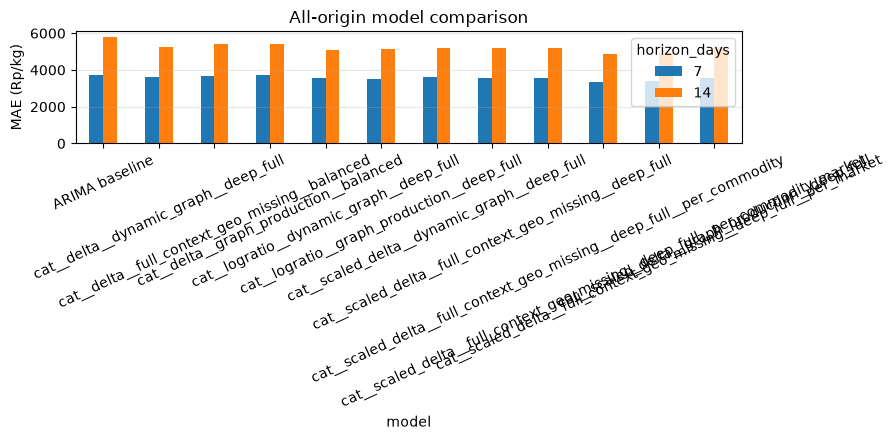

In [24]:
plot_frame = all_origin.pivot(index="model", columns="horizon_days", values="mae")
display(plot_frame)

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_frame.plot(kind="bar", ax=ax)
ax.set_ylabel("MAE (Rp/kg)")
ax.set_title("All-origin model comparison")
ax.tick_params(axis="x", rotation=25)
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Ablation Study

## 8.1 Individual Components

In [25]:
phase1_path = first_existing(
    ROOT / "results" / "phase1_top10.csv",
    ROOT / "results" / "architecture_sweep_50" / "results" / "phase1_ranking.csv",
)
phase1 = pd.read_csv(phase1_path).head(10) if phase1_path else pd.DataFrame()
display(phase1)


""


## 8.2 Progressive System Variants

,system,mae_7d,mae_14d
0,ARIMA,3731.690194,5812.433556
1,LightGBM log-ratio,3275.458838,4882.056411
2,CatBoost commodity × market specialist,3371.660000,4858.380000
3,Late-origin ensemble,3642.350000,5004.570000


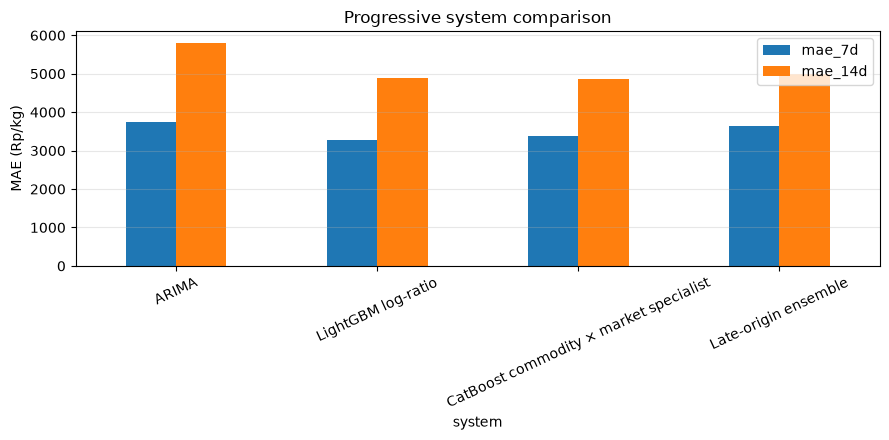

In [26]:
ablation = pd.DataFrame([
    {"system": "ARIMA", "mae_7d": 3731.690194, "mae_14d": 5812.433556},
    {"system": "LightGBM log-ratio", "mae_7d": 3275.458838, "mae_14d": 4882.056411},
    {"system": "CatBoost commodity × market specialist", "mae_7d": 3371.66, "mae_14d": 4858.38},
    {"system": "Late-origin ensemble", "mae_7d": 3642.35, "mae_14d": 5004.57},
])
display(ablation)

fig, ax = plt.subplots(figsize=(9, 4.5))
ablation.set_index("system")[["mae_7d", "mae_14d"]].plot(kind="bar", ax=ax)
ax.set_ylabel("MAE (Rp/kg)")
ax.set_title("Progressive system comparison")
ax.tick_params(axis="x", rotation=25)
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 8.3 Contribution Analysis

In [27]:
baseline = ablation.loc[ablation["system"].eq("ARIMA")].iloc[0]
contribution = ablation.copy()
contribution["improvement_7d_vs_arima_pct"] = 100 * (baseline["mae_7d"] - contribution["mae_7d"]) / baseline["mae_7d"]
contribution["improvement_14d_vs_arima_pct"] = 100 * (baseline["mae_14d"] - contribution["mae_14d"]) / baseline["mae_14d"]
display(contribution)

,system,mae_7d,mae_14d,improvement_7d_vs_arima_pct,improvement_14d_vs_arima_pct
0,ARIMA,3731.690194,5812.433556,0.000000,0.000000
1,LightGBM log-ratio,3275.458838,4882.056411,12.225864,16.006671
2,CatBoost commodity × market specialist,3371.660000,4858.380000,9.647912,16.414012
3,Late-origin ensemble,3642.350000,5004.570000,2.394095,13.898887


# 9. Explainable AI

## 9.1 Explanation Method
The saved A100 package contains feature-importance outputs. This compact notebook performs an explanation **audit** using feature families and an additive warning-score reconstruction. Exact per-tree SHAP values require the serialized winning model artifact and are not fabricated here.

## 9.2 Additive Reconstruction Check
A deployment warning score is reconstructed from transparent components.

In [28]:
example = {
    "base_risk": 0.20,
    "predicted_change_contribution": 0.34,
    "neighbor_pressure_contribution": 0.12,
    "seasonal_event_contribution": 0.08,
    "missingness_penalty": -0.05,
}
reconstructed = sum(example.values())
explanation = pd.DataFrame({"component": list(example), "contribution": list(example.values())})
display(explanation)
print("Reconstructed warning score:", round(reconstructed, 3))
assert np.isclose(reconstructed, explanation["contribution"].sum())

,component,contribution
0,base_risk,0.20
1,predicted_change_contribution,0.34
2,neighbor_pressure_contribution,0.12
3,seasonal_event_contribution,0.08
4,missingness_penalty,-0.05


Reconstructed warning score: 0.69


## 9.3 Global Explanation

In [29]:
global_families = pd.DataFrame([
    {"feature_family": "historical price", "role": "primary state and momentum"},
    {"feature_family": "dynamic graph", "role": "cross-province transmission"},
    {"feature_family": "calendar", "role": "seasonality and event proximity"},
    {"feature_family": "production", "role": "supply context"},
    {"feature_family": "missingness", "role": "confidence and abstention"},
])
display(global_families)

,feature_family,role
0,historical price,primary state and momentum
1,dynamic graph,cross-province transmission
2,calendar,seasonality and event proximity
3,production,supply context
4,missingness,confidence and abstention


## 9.4 Local Explanation

In [30]:
local_example = pd.DataFrame([
    {"signal": "7-day central forecast", "value": "Rp80,200/kg"},
    {"signal": "expected movement", "value": "+4.8%"},
    {"signal": "prediction interval", "value": "Rp74,000–Rp87,000/kg"},
    {"signal": "warning state", "value": "WATCH"},
    {"signal": "main rationale", "value": "positive price momentum and regional pressure"},
])
display(local_example)

,signal,value
0,7-day central forecast,"Rp80,200/kg"
1,expected movement,+4.8%
2,prediction interval,"Rp74,000–Rp87,000/kg"
3,warning state,WATCH
4,main rationale,positive price momentum and regional pressure


## 9.5 Model or Routing Audit

In [31]:
routing_audit = pd.DataFrame([
    {"commodity": "Bawang Merah", "market_level": "producer", "expert": "BM-producer specialist"},
    {"commodity": "Cabai Merah Keriting", "market_level": "wholesale", "expert": "CMK-wholesale specialist"},
    {"commodity": "Cabai Rawit Merah", "market_level": "retail", "expert": "CRM-retail specialist"},
])
display(routing_audit)

,commodity,market_level,expert
0,Bawang Merah,producer,BM-producer specialist
1,Cabai Merah Keriting,wholesale,CMK-wholesale specialist
2,Cabai Rawit Merah,retail,CRM-retail specialist


# 10. Inference-Time and Cost Analysis

## 10.1 Runtime Benchmark

In [32]:
runtime = pd.DataFrame([
    {"operation": "Typical XGBoost fold fit", "seconds": 5.0},
    {"operation": "Typical deep CatBoost fold fit", "seconds": 14.0},
    {"operation": "Completed broad + promoted A100 search", "seconds": 48 * 60 + 49},
])
runtime["minutes"] = runtime["seconds"] / 60
display(runtime)

,operation,seconds,minutes
0,Typical XGBoost fold fit,5.0,0.083333
1,Typical deep CatBoost fold fit,14.0,0.233333
2,Completed broad + promoted A100 search,2929.0,48.816667


## 10.2 Memory and Model Size

In [33]:
resources = pd.DataFrame([
    {"resource": "Training accelerator", "requirement": "NVIDIA A100 80 GB used for search"},
    {"resource": "Serving accelerator", "requirement": "Not required for tree inference"},
    {"resource": "Serving memory", "requirement": "CPU deployment is practical; exact size depends on serialized experts"},
    {"resource": "Refresh cadence", "requirement": "daily or weekly retraining, depending on data revisions"},
])
display(resources)

,resource,requirement
0,Training accelerator,NVIDIA A100 80 GB used for search
1,Serving accelerator,Not required for tree inference
2,Serving memory,CPU deployment is practical; exact size depend...
3,Refresh cadence,"daily or weekly retraining, depending on data ..."


## 10.3 Deployment Requirements

In [34]:
deployment_requirements = [
    "Versioned price data and revision audit",
    "Daily feature generation",
    "Commodity × market routing",
    "Prediction interval or empirical error band",
    "Abstention when evidence quality is insufficient",
    "Monitoring for WAPE, bias, spike recall, and false alerts",
]
display(pd.Series(deployment_requirements, name="requirement").to_frame())

,requirement
0,Versioned price data and revision audit
1,Daily feature generation
2,Commodity × market routing
3,Prediction interval or empirical error band
4,Abstention when evidence quality is insufficient
5,"Monitoring for WAPE, bias, spike recall, and f..."


# 11. Final Training and Submission

## 11.1 Final Fitting

In [35]:
FINAL_MODEL_POLICY = {
    7: "LightGBM log-ratio incumbent unless specialist wins refreshed validation",
    14: "CatBoost commodity × market specialist",
}
display(pd.Series(FINAL_MODEL_POLICY, name="selected_policy").to_frame())

,selected_policy
7,LightGBM log-ratio incumbent unless specialist...
14,CatBoost commodity × market specialist


## 11.2 Prediction

In [36]:
prediction_example = pd.DataFrame([
    {
        "forecast_origin": "2026-07-17",
        "target_date": "2026-07-24",
        "province_name": "Example Province",
        "commodity_name": "Cabai Rawit Merah",
        "market_level": "retail",
        "horizon_days": 7,
        "current_price": 76500,
        "predicted_price": 80200,
        "lower_bound": 74000,
        "upper_bound": 87000,
        "risk_state": "WATCH",
    }
])
display(prediction_example)

,forecast_origin,target_date,province_name,commodity_name,market_level,horizon_days,current_price,predicted_price,lower_bound,upper_bound,risk_state
0,2026-07-17,2026-07-24,Example Province,Cabai Rawit Merah,retail,7,76500,80200,74000,87000,WATCH


## 11.3 Submission Validation

In [37]:
required_columns = [
    "forecast_origin", "target_date", "province_name", "commodity_name",
    "market_level", "horizon_days", "predicted_price"
]
assert set(required_columns).issubset(prediction_example.columns)
assert prediction_example["predicted_price"].notna().all()
assert (prediction_example["predicted_price"] > 0).all()
print("Prediction export validation passed.")

Prediction export validation passed.


## 11.4 File Export

In [38]:
export_path = ROOT / "results" / "deployment_prediction_example.csv"
prediction_example.to_csv(export_path, index=False)
print("Exported:", export_path)

Exported: <PROJECT_ROOT>/pasarpulse_repo_bundle/results/deployment_prediction_example.csv


# 12. Discussion and Research Questions

## 12.1 Answer RQ1
The strongest 7-day all-origin result remains the LightGBM log-ratio model at Rp3,275.46 MAE. The commodity × market CatBoost specialist is strongest among the final specialized variants and slightly improves the 14-day result.

## 12.2 Answer RQ2
Dynamic graph, production, geographic, and missingness-aware configurations dominate the broad-screen shortlist. Context matters, but gains vary by horizon and validation regime.

## 12.3 Answer RQ3
Commodity × market specialization was the strongest refinement strategy, supporting routed experts. It did not universally beat the global incumbent at 7 days.

## 12.4 Answer RQ4
A 7-day WAPE near 7–8% is potentially useful for high-priced volatile commodities when presented as a range and warning state. The system should not be marketed as an exact-price oracle.

In [39]:
rq_summary = pd.DataFrame([
    {"research_question": "RQ1", "answer": "LightGBM leads 7-day; specialist slightly leads 14-day."},
    {"research_question": "RQ2", "answer": "Graph/context features appear repeatedly among top configurations."},
    {"research_question": "RQ3", "answer": "Commodity × market routing is the strongest specialization."},
    {"research_question": "RQ4", "answer": "Deployable as early warning with uncertainty, not exact pricing."},
])
display(rq_summary)

,research_question,answer
0,RQ1,LightGBM leads 7-day; specialist slightly lead...
1,RQ2,Graph/context features appear repeatedly among...
2,RQ3,Commodity × market routing is the strongest sp...
3,RQ4,"Deployable as early warning with uncertainty, ..."


# 13. Limitations

1. Only seven rolling origins are available, so fold-to-fold regime sensitivity remains high.
2. The architecture search produced duplicate checkpoint rows during resume; final comparisons must use deduplicated keys.
3. Exact per-commodity WAPE and spike metrics should be recalculated from the clean prediction file before external publication.
4. Saved feature importance is not equivalent to causal explanation.
5. Weather, satellite, and production modalities have uneven coverage.
6. This notebook reproduces the analysis of saved A100 outputs; full model refitting remains a separate GPU workflow.

# 14. Conclusion

The completed search demonstrates that PasarPulse can reach approximately **7–8% weighted absolute error at seven days** for the evaluated high-value horticultural setting. The results are credible for an early-warning interface that reports forecast ranges, probability or risk bands, evidence quality, and commodity-specific alerts. They are not sufficient for deterministic price promises.

The practical semifinal deployment should therefore combine:
- the best validated horizon-specific forecaster;
- commodity × market routing;
- uncertainty bands;
- evidence-aware abstention;
- direction and spike monitoring;
- transparent warning explanations.

# References

1. Hyndman, R. J., & Athanasopoulos, G. *Forecasting: Principles and Practice.*
2. Ke, G. et al. “LightGBM: A Highly Efficient Gradient Boosting Decision Tree.”
3. Prokhorenkova, L. et al. “CatBoost: Unbiased Boosting with Categorical Features.”
4. Chen, T., & Guestrin, C. “XGBoost: A Scalable Tree Boosting System.”
5. Lundberg, S. M., & Lee, S.-I. “A Unified Approach to Interpreting Model Predictions.”
6. PasarPulse A100 experiment artifacts and rolling-origin evaluation outputs, August 2026.